In [1]:
import pandas as pd
import numpy as np

Loading our data after importing our libraries.
Users might or might not have gotten their money back, and most of them have not paid the money back, hence why some of those spots are empty

In [2]:
cash_df = pd.read_csv("project_dataset/extract - cash request - data analyst.csv")
fees_df = pd.read_csv("project_dataset/extract - fees - data analyst - .csv")
cash_df_copy = cash_df.copy()
fees_df_copy = fees_df.copy()

In [3]:
cash_df_copy = cash_df_copy.dropna(subset=['send_at'])

In [4]:
cash_df_copy.head()


,id,amount,status,created_at,updated_at,user_id,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update
48,23534,25.0,money_back,2020-10-23 15:20:26.163927+00,2020-12-18 13:08:29.099365+00,21465.0,NaN,NaN,2020-11-10 23:51:00+00,NaN,2020-11-06 07:16:21.845479+00,instant,2020-10-23 15:21:26.878525+00,NaN,NaN,NaN
55,9323,50.0,rejected,2020-07-21 21:33:12.430494+00,2020-07-22 08:59:33.989211+00,23318.0,2020-07-22 08:59:33.986846+00,NaN,2020-08-05 22:00:00+00,NaN,NaN,regular,2020-07-28 21:33:12.430087+00,NaN,NaN,NaN
60,18701,100.0,rejected,2020-10-01 11:41:07.208207+00,2020-10-01 12:26:23.482538+00,57285.0,2020-10-01 12:26:23.47496+00,NaN,2020-11-04 22:00:00+00,NaN,NaN,regular,2020-10-08 11:41:07.170136+00,NaN,NaN,NaN
62,16121,50.0,rejected,2020-09-14 23:05:32.606904+00,2020-09-15 08:16:28.688342+00,38075.0,2020-09-15 08:16:28.681129+00,NaN,2020-10-05 22:00:00+00,NaN,NaN,instant,2020-09-21 23:05:32.558375+00,NaN,NaN,NaN
135,18459,100.0,rejected,2020-09-29 18:36:25.875659+00,2020-09-30 07:51:52.005581+00,55584.0,2020-09-30 07:51:51.997203+00,NaN,2020-10-07 22:00:00+00,NaN,NaN,instant,2020-10-06 18:36:25.849957+00,NaN,NaN,NaN


In [5]:
# cash_df_copy.isnull().sum()
# Converting 'send_at' to datetime
cash_df_copy['send_at'] = pd.to_datetime(cash_df_copy['send_at'], errors='coerce')

In [6]:
# Create request month, extracted from send_at. Assign cohort month (first usage month per user)
cash_df_copy['request_month'] = (
    cash_df_copy['send_at'].dt.tz_localize(None).dt.to_period('M')
)

cash_df_copy['cohort_month'] = cash_df_copy.groupby('user_id')['request_month'].transform('min')

cash_df_copy = cash_df_copy.dropna(subset=['request_month', 'cohort_month'])

# Calculate months since cohort
cash_df_copy['months_since_cohort'] = (
    cash_df_copy['request_month'] - cash_df_copy['cohort_month']
).apply(lambda x: x.n)


cash_df_copy = cash_df_copy.rename(columns={'cohort_month':'cohorts'})
# Count requests per cohort per month
cohort = cash_df_copy.groupby(['cohorts', 'months_since_cohort']).size().unstack(fill_value=0)

display(cohort)

months_since_cohort,0,1,2,3,4
cohorts,,,,,
2020-07,417,292,182,193,2
2020-08,3004,1242,1405,40,0
2020-09,1357,636,27,0,0
2020-10,6363,47,0,0,0
2020-11,169,0,0,0,0


In [7]:
cash_df_copy.head()

,id,amount,status,created_at,updated_at,user_id,moderated_at,deleted_account_id,reimbursement_date,cash_request_received_date,money_back_date,transfer_type,send_at,recovery_status,reco_creation,reco_last_update,request_month,cohorts,months_since_cohort
48,23534,25.0,money_back,2020-10-23 15:20:26.163927+00,2020-12-18 13:08:29.099365+00,21465.0,NaN,NaN,2020-11-10 23:51:00+00,NaN,2020-11-06 07:16:21.845479+00,instant,2020-10-23 15:21:26.878525+00:00,NaN,NaN,NaN,2020-10,2020-09,1
55,9323,50.0,rejected,2020-07-21 21:33:12.430494+00,2020-07-22 08:59:33.989211+00,23318.0,2020-07-22 08:59:33.986846+00,NaN,2020-08-05 22:00:00+00,NaN,NaN,regular,2020-07-28 21:33:12.430087+00:00,NaN,NaN,NaN,2020-07,2020-07,0
60,18701,100.0,rejected,2020-10-01 11:41:07.208207+00,2020-10-01 12:26:23.482538+00,57285.0,2020-10-01 12:26:23.47496+00,NaN,2020-11-04 22:00:00+00,NaN,NaN,regular,2020-10-08 11:41:07.170136+00:00,NaN,NaN,NaN,2020-10,2020-10,0
62,16121,50.0,rejected,2020-09-14 23:05:32.606904+00,2020-09-15 08:16:28.688342+00,38075.0,2020-09-15 08:16:28.681129+00,NaN,2020-10-05 22:00:00+00,NaN,NaN,instant,2020-09-21 23:05:32.558375+00:00,NaN,NaN,NaN,2020-09,2020-09,0
135,18459,100.0,rejected,2020-09-29 18:36:25.875659+00,2020-09-30 07:51:52.005581+00,55584.0,2020-09-30 07:51:51.997203+00,NaN,2020-10-07 22:00:00+00,NaN,NaN,instant,2020-10-06 18:36:25.849957+00:00,NaN,NaN,NaN,2020-10,2020-10,0


In [8]:
# fees_cohorts = fees_df_copy.groupby(['cohorts', 'months_since_cohort']).size().unstack(fill_value=0)

display(cohort)

months_since_cohort,0,1,2,3,4
cohorts,,,,,
2020-07,417,292,182,193,2
2020-08,3004,1242,1405,40,0
2020-09,1357,636,27,0,0
2020-10,6363,47,0,0,0
2020-11,169,0,0,0,0


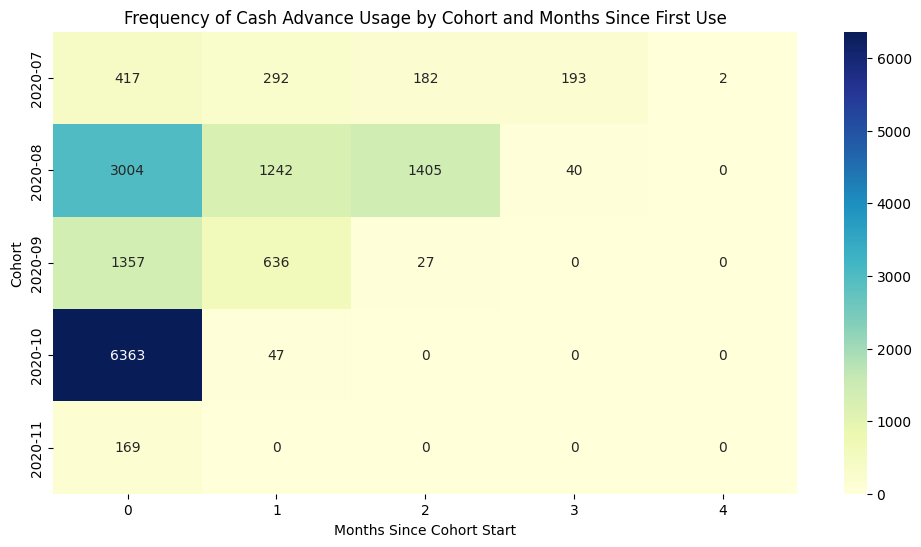

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Using the heatmap function of seaborn to show the collected data

plt.figure(figsize=(12, 6))
sns.heatmap(cohort, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Frequency of Cash Advance Usage by Cohort and Months Since First Use')
plt.xlabel('Months Since Cohort Start')
plt.ylabel('Cohort')
plt.show()

In [10]:
# Dropping the duplicates in the fees dataframe
#fees_df_copy = fees_df_copy.drop_duplicates(subset='cash_request_id')


In [11]:
cash_df_copy.columns

Index(['id', 'amount', 'status', 'created_at', 'updated_at', 'user_id',
       'moderated_at', 'deleted_account_id', 'reimbursement_date',
       'cash_request_received_date', 'money_back_date', 'transfer_type',
       'send_at', 'recovery_status', 'reco_creation', 'reco_last_update',
       'request_month', 'cohorts', 'months_since_cohort'],
      dtype='object')

In [12]:
# merging tables

merged_df = cash_df_copy.merge(
    fees_df_copy,
    how='left',
    left_on='id',               # key of cash_id
    right_on='cash_request_id'  # key of fees
    ) 

In [13]:
incidents = merged_df.groupby(['cohorts', 'type']).size().unstack(fill_value=0)

In [14]:
incidents.head()

type,incident,instant_payment,postpone
cohorts,,,
2020-07,115,420,320
2020-08,602,3151,2052
2020-09,135,1291,836
2020-10,132,5760,1896
2020-11,0,69,0


In [15]:
cohorts_total = incidents.sum(axis=1)
incident_rate = incidents.divide(cohorts_total, axis=0)

In [16]:
display(incident_rate)

type,incident,instant_payment,postpone
cohorts,,,
2020-07,0.134503,0.491228,0.374269
2020-08,0.103704,0.542808,0.353488
2020-09,0.059682,0.570734,0.369584
2020-10,0.016949,0.739599,0.243451
2020-11,0.000000,1.000000,0.000000


In [17]:
incident_rate_reset = incident_rate.reset_index()


In [18]:
incident_long = incident_rate_reset.melt(
    id_vars='cohorts',            # we keep this column as-is
    var_name='type',              # name for the variable column (was column names)
    value_name='rate'             # name for the values (rates)
)

In [19]:
display(incident_long)

,cohorts,type,rate
0,2020-07,incident,0.134503
1,2020-08,incident,0.103704
2,2020-09,incident,0.059682
3,2020-10,incident,0.016949
4,2020-11,incident,0.000000
5,2020-07,instant_payment,0.491228
6,2020-08,instant_payment,0.542808
7,2020-09,instant_payment,0.570734
8,2020-10,instant_payment,0.739599
9,2020-11,instant_payment,1.000000


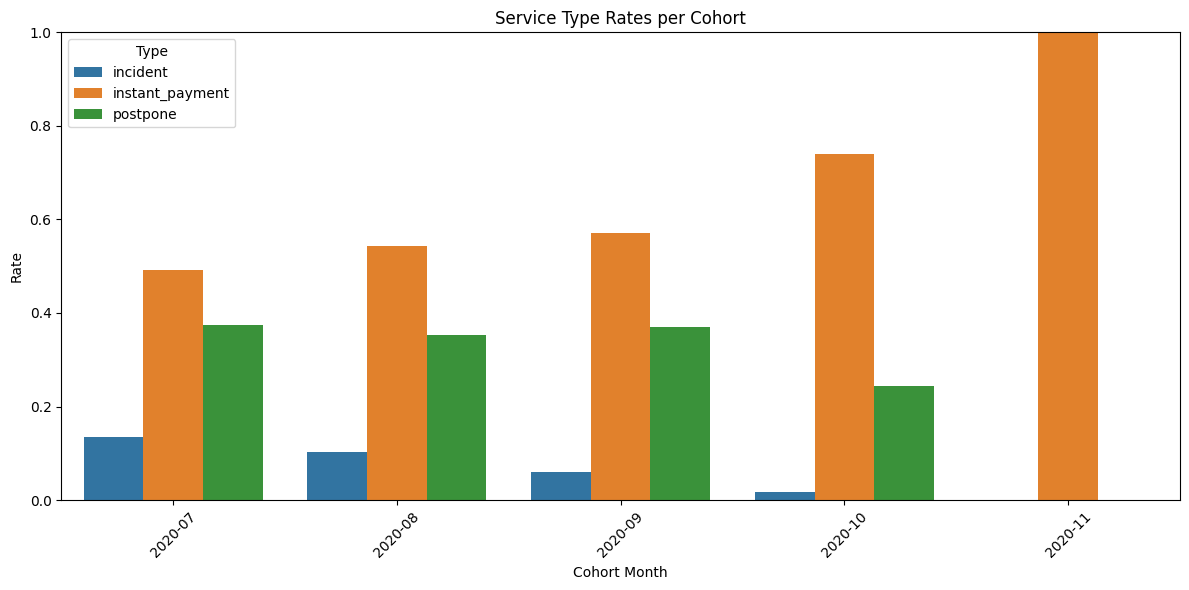

In [20]:
plt.figure(figsize=(12, 6))

sns.barplot(data=incident_long, x='cohorts', y='rate', hue='type')

# I asked Chat GPT to write this down below for me so it's a clearer graph
plt.title('Service Type Rates per Cohort')
plt.ylabel('Rate')
plt.xlabel('Cohort Month')
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

In [21]:
revenue_df = merged_df.dropna(subset=['total_amount'])


In [22]:
cohort_revenue = (
    revenue_df
    .groupby(['cohorts', 'request_month'])['total_amount']
    .sum()
    .unstack(fill_value=0)
)

display(cohort_revenue)

request_month,2020-07,2020-08,2020-09,2020-10,2020-11
cohorts,,,,,
2020-07,830.0,1400.0,995.0,1045.0,5.0
2020-08,0.0,15040.0,6425.0,7495.0,65.0
2020-09,0.0,0.0,7650.0,3600.0,60.0
2020-10,0.0,0.0,0.0,38835.0,105.0
2020-11,0.0,0.0,0.0,0.0,345.0


C:\Users\pktto\AppData\Local\Temp\ipykernel_27552\2616301485.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cohort_total_revenue, x="Cohort", y="Total Revenue", palette='magma')


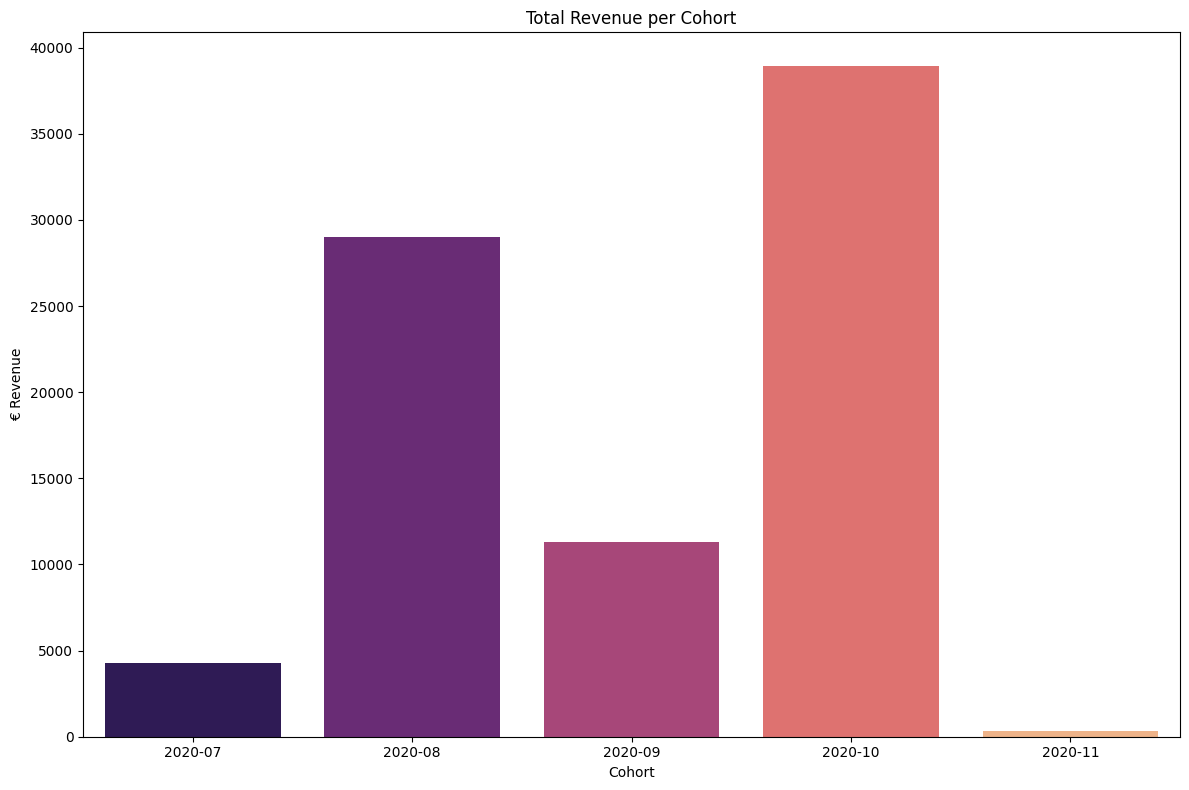

In [23]:
cohort_total_revenue = cohort_revenue.sum(axis=1).reset_index()
cohort_total_revenue.columns = ["Cohort", "Total Revenue"]
plt.figure(figsize=(12, 8))
sns.barplot(data=cohort_total_revenue, x="Cohort", y="Total Revenue", palette='magma')
plt.title("Total Revenue per Cohort")
plt.ylabel("€ Revenue")
plt.xlabel("Cohort")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()